# Clyvo Vet — Vigia C: alerta regional

# Parte 1 — Análise exploratória

## 1. Importação das bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from clyvo_regional import (carregar_casos, filtrar_especie_alvo, montar_janelas, calcular_estatisticas,
                            gerar_alertas_regionais, alertas_caso_unico, treinar_isolation_forest, marcar_anomalias,
                            avaliar_regioes,
                            doencas_em_surto_por_regiao, LIMIAR, JANELA_DIAS, DATA_REFERENCIA, FEATURES_IF, MIN_JANELAS_HISTORICO,
                            em_pico, texto_pico)

pd.set_option("display.max_colwidth", 140)

## 2. Carregando os diagnósticos

In [2]:
casos, origem = carregar_casos()
print(f"Origem: {origem} | {len(casos)} diagnósticos de {casos['dt_consulta'].min()} a {casos['dt_consulta'].max()}")
print(f"Data de referência da análise: {DATA_REFERENCIA}")
casos.head()

Origem: CSV | 437 diagnósticos de 2024-10-01 a 2026-10-03
Data de referência da análise: 2026-10-04


,dt_consulta,cidade,bairro,especie_animal,nm_doenca,especie_alvo,contagiosa,monitora_surto,alerta_caso_unico,mes_inicio_pico,mes_fim_pico
0,2025-02-07,Sao Paulo,Lapa,Canina,Cinomose,Canina,S,S,N,NaN,NaN
1,2025-07-14,Sao Paulo,Lapa,Canina,Cinomose,Canina,S,S,N,NaN,NaN
2,2026-07-18,Sao Paulo,Lapa,Canina,Tosse dos canis (gripe canina),Canina,S,S,N,NaN,NaN
3,2025-12-09,Sao Paulo,Lapa,Canina,Leptospirose,Canina,S,S,N,10.0,3.0
4,2025-11-26,Sao Paulo,Lapa,Canina,Tosse dos canis (gripe canina),Canina,S,S,N,NaN,NaN


### Diagnósticos por doença

In [3]:
resumo = (casos.groupby(["nm_doenca", "especie_alvo", "contagiosa", "monitora_surto", "alerta_caso_unico"])
          .size().rename("diagnósticos").reset_index().sort_values("diagnósticos", ascending=False))
resumo

,nm_doenca,especie_alvo,contagiosa,monitora_surto,alerta_caso_unico,diagnósticos
2,Erliquiose (doença do carrapato),Canina,N,S,N,88
10,Tosse dos canis (gripe canina),Canina,S,S,N,82
7,Parvovirose,Canina,S,S,N,71
5,Leptospirose,Canina,S,S,N,53
1,Cinomose,Canina,S,S,N,47
9,Rinotraqueite felina,Felina,S,S,N,28
3,Esporotricose,Felina,S,S,N,22
6,Panleucopenia felina,Felina,S,S,N,22
0,Calicivirose felina,Felina,S,N,N,15
4,Hepatite infecciosa canina,Canina,S,N,N,8


## 3. Filtro de espécie-alvo (correlação 13)

In [4]:
filtrados = filtrar_especie_alvo(casos)
print("Diagnósticos antes do filtro:", len(casos))
print("Diagnósticos após o filtro:  ", len(filtrados))
pd.crosstab(filtrados["nm_doenca"], filtrados["especie_animal"])

Diagnósticos antes do filtro: 437
Diagnósticos após o filtro:   437


especie_animal,Canina,Felina
nm_doenca,,
Calicivirose felina,0,15
Cinomose,47,0
Erliquiose (doença do carrapato),88,0
Esporotricose,0,22
Hepatite infecciosa canina,8,0
Leptospirose,53,0
Panleucopenia felina,0,22
Parvovirose,71,0
Raiva,0,1


# Parte 2 — Detecção de surtos

## 4. Casos por bairro (2 anos) em janelas de 14 dias (correlação 11)

In [5]:
janelas = montar_janelas(casos)
print("Linhas (bairro x doença x espécie x janela):", len(janelas))
janelas[janelas["casos"] > 0].head(10)

Linhas (bairro x doença x espécie x janela): 4028


,cidade,bairro,doenca,especie,janela,inicio,fim,casos,contagiosa,mes_inicio_pico,mes_fim_pico
0,Sao Paulo,Lapa,Cinomose,Canina,0,2026-09-21,2026-10-04,8,S,NaN,NaN
9,Sao Paulo,Lapa,Cinomose,Canina,9,2026-05-18,2026-05-31,1,S,NaN,NaN
29,Sao Paulo,Lapa,Cinomose,Canina,29,2025-08-11,2025-08-24,1,S,NaN,NaN
31,Sao Paulo,Lapa,Cinomose,Canina,31,2025-07-14,2025-07-27,1,S,NaN,NaN
36,Sao Paulo,Lapa,Cinomose,Canina,36,2025-05-05,2025-05-18,1,S,NaN,NaN
43,Sao Paulo,Lapa,Cinomose,Canina,43,2025-01-27,2025-02-09,2,S,NaN,NaN
48,Sao Paulo,Lapa,Cinomose,Canina,48,2024-11-18,2024-12-01,1,S,NaN,NaN
49,Sao Paulo,Lapa,Cinomose,Canina,49,2024-11-04,2024-11-17,1,S,NaN,NaN
53,Sao Paulo,Lapa,Tosse dos canis (gripe canina),Canina,0,2026-09-21,2026-10-04,1,S,NaN,NaN
58,Sao Paulo,Lapa,Tosse dos canis (gripe canina),Canina,5,2026-07-13,2026-07-26,1,S,NaN,NaN


### 4.1 Como um surto aparece nos dados: cinomose na Lapa e esporotricose no Tatuapé

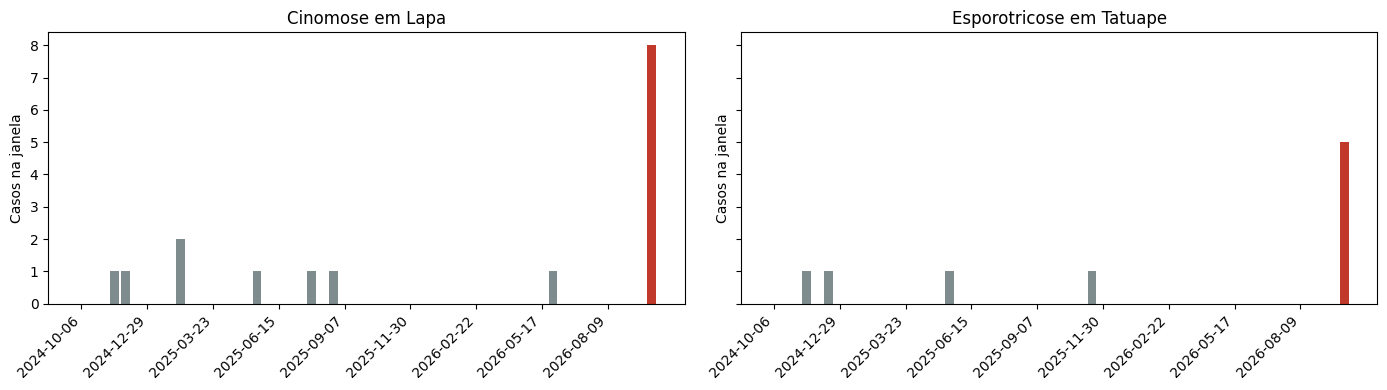

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for eixo, (bairro, doenca) in zip(eixos, [("Lapa", "Cinomose"), ("Tatuape", "Esporotricose")]):
    serie = (janelas[(janelas["bairro"] == bairro) & (janelas["doenca"] == doenca)]
             .sort_values("janela", ascending=False))
    cores = ["#c0392b" if j == 0 else "#7f8c8d" for j in serie["janela"]]
    eixo.bar(serie["fim"].astype(str), serie["casos"], color=cores)
    eixo.set_title(f"{doenca} em {bairro}")
    eixo.set_xticks(range(0, len(serie), 6))
    eixo.set_xticklabels(serie["fim"].astype(str).iloc[::6], rotation=45, ha="right")
    eixo.set_ylabel("Casos na janela")
plt.tight_layout()
plt.show()

## 5. Z-score: base para identificar surto

In [7]:
tabela = calcular_estatisticas(janelas)
atual = tabela[tabela["janela"] == 0].sort_values("z", ascending=False)
atual[["bairro", "doenca", "especie", "casos", "media_hist", "desvio_hist", "z", "contagiosa", "em_pico"]].head(10).round(2)

,bairro,doenca,especie,casos,media_hist,desvio_hist,z,contagiosa,em_pico
795,Lapa,Cinomose,Canina,8,0.15,0.41,15.69,S,False
3286,Tatuape,Esporotricose,Felina,5,0.08,0.27,9.85,S,False
1113,Lapa,Tosse dos canis (gripe canina),Canina,1,0.10,0.35,1.81,S,False
2650,Pinheiros,Parvovirose,Canina,1,0.10,0.29,1.81,S,False
1749,Penha,Leptospirose,Canina,1,0.10,0.29,1.81,S,True
3233,Tatuape,Erliquiose (doença do carrapato),Canina,1,0.13,0.34,1.73,N,False
636,Ipiranga,Parvovirose,Canina,1,0.21,0.49,1.58,S,False
477,Ipiranga,Erliquiose (doença do carrapato),Canina,1,0.23,0.42,1.54,N,False
2014,Perdizes,Cinomose,Canina,0,0.02,0.14,-0.04,S,False
1060,Lapa,Rinotraqueite felina,Felina,0,0.02,0.14,-0.04,S,False


## 6. Limiares por contágio (correlação 14)

In [8]:
pd.DataFrame(LIMIAR).T.rename(index={"S": "Contagiosa", "N": "Não contagiosa (erliquiose)"},
                              columns={"z": "z mínimo", "casos_min": "casos mínimos na janela"})

,z mínimo,casos mínimos na janela
Contagiosa,2.0,2.0
Não contagiosa (erliquiose),3.0,4.0


### 6.1 Época de pico (correlação 12)

In [9]:
mes_atual = DATA_REFERENCIA.month
monitoradas = (casos[casos["monitora_surto"] == "S"]
               .drop_duplicates("nm_doenca")[["nm_doenca", "especie_alvo", "contagiosa", "mes_inicio_pico", "mes_fim_pico"]]
               .copy())
monitoradas["época de pico"] = [texto_pico(i, f) if not pd.isna(i) else "-"
                                for i, f in zip(monitoradas["mes_inicio_pico"], monitoradas["mes_fim_pico"])]
monitoradas["em pico agora?"] = [em_pico(mes_atual, i, f)
                                 for i, f in zip(monitoradas["mes_inicio_pico"], monitoradas["mes_fim_pico"])]
monitoradas.drop(columns=["mes_inicio_pico", "mes_fim_pico"]).reset_index(drop=True)

,nm_doenca,especie_alvo,contagiosa,época de pico,em pico agora?
0,Cinomose,Canina,S,-,False
1,Tosse dos canis (gripe canina),Canina,S,-,False
2,Leptospirose,Canina,S,outubro a março,True
3,Parvovirose,Canina,S,-,False
4,Erliquiose (doença do carrapato),Canina,N,-,False
5,Panleucopenia felina,Felina,S,-,False
6,Rinotraqueite felina,Felina,S,-,False
7,Esporotricose,Felina,S,-,False


## 7. Alertas da janela atual

In [10]:
alertas_atuais = gerar_alertas_regionais(tabela, janela=0)
alertas_atuais[["bairro", "doenca", "especie", "casos", "media_hist", "z", "nivel_risco", "motivo"]].round(2)

,bairro,doenca,especie,casos,media_hist,z,nivel_risco,motivo
795,Lapa,Cinomose,Canina,8,0.15,15.69,ALTO,"8 casos de Cinomose em Lapa nos últimos 14 dias (média histórica de 0,2 caso(s) a cada 14 dias; doença contagiosa)."
3286,Tatuape,Esporotricose,Felina,5,0.08,9.85,ALTO,"5 casos de Esporotricose em Tatuape nos últimos 14 dias (média histórica de 0,1 caso(s) a cada 14 dias; doença contagiosa)."
1749,Penha,Leptospirose,Canina,1,0.10,1.81,BAIXO,1 caso(s) de Leptospirose em Penha durante a época de maior incidência (outubro a março). Alerta preventivo.


### 7.1 Raiva: alerta com um único caso

In [11]:
raiva = alertas_caso_unico(casos)
raiva[["bairro", "doenca", "especie", "casos", "nivel_risco", "motivo"]]

,bairro,doenca,especie,casos,nivel_risco,motivo
0,Butanta,Raiva,Canina,1,ALTO,"Suspeita de raiva em Butanta (1 gato, nos últimos 14 dias). Alerta imediato: doença fatal, transmissível a humanos e de notificação obri..."
1,Butanta,Raiva,Felina,1,ALTO,"Suspeita de raiva em Butanta (1 gato, nos últimos 14 dias). Alerta imediato: doença fatal, transmissível a humanos e de notificação obri..."


### 7.2 Alertas por janela no histórico (análise retrospectiva)

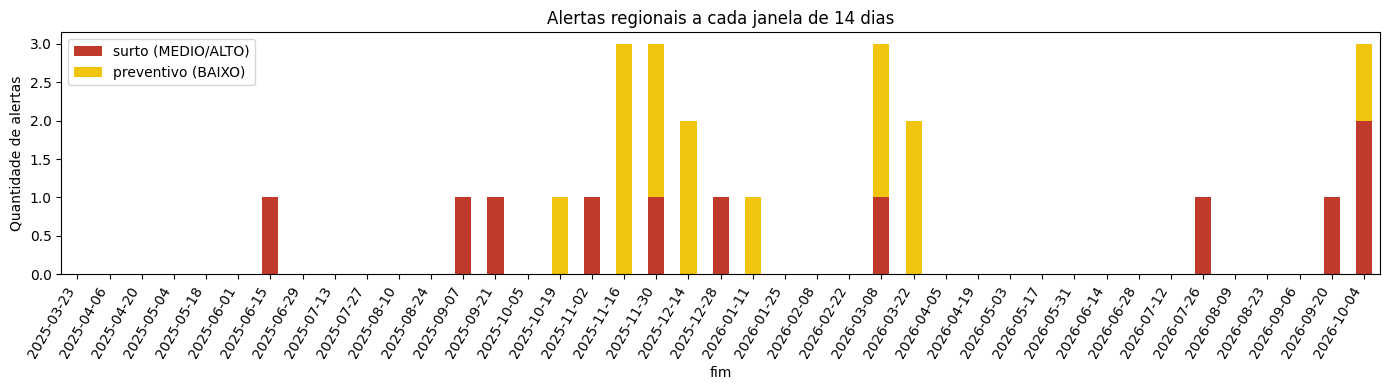

Média de alertas de surto por janela no passado: 0.22
Média de alertas preventivos por janela no passado: 0.32


In [12]:
historico_alertas = []
for j in range(0, int(tabela["janela"].max()) - MIN_JANELAS_HISTORICO + 1):
    a = gerar_alertas_regionais(tabela, janela=j)
    historico_alertas.append({"janela": j, "fim": tabela.loc[tabela["janela"] == j, "fim"].iloc[0],
                              "surto (MEDIO/ALTO)": int((a["nivel_risco"] != "BAIXO").sum()),
                              "preventivo (BAIXO)": int((a["nivel_risco"] == "BAIXO").sum())})
historico_alertas = pd.DataFrame(historico_alertas).sort_values("janela", ascending=False)

historico_alertas.set_index(historico_alertas["fim"].astype(str))[["surto (MEDIO/ALTO)", "preventivo (BAIXO)"]] \
    .plot(kind="bar", stacked=True, figsize=(14, 4), color=["#c0392b", "#f1c40f"])
plt.title("Alertas regionais a cada janela de 14 dias")
plt.ylabel("Quantidade de alertas")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

passado = historico_alertas.query("janela > 0")
print("Média de alertas de surto por janela no passado:", round(passado["surto (MEDIO/ALTO)"].mean(), 2))
print("Média de alertas preventivos por janela no passado:", round(passado["preventivo (BAIXO)"].mean(), 2))

## 8. Isolation Forest

### 8.1 Treinamento com o histórico

In [13]:
modelo_if = treinar_isolation_forest(tabela)
pontos_if = marcar_anomalias(tabela, modelo_if)
historico_if = pontos_if[pontos_if["janela"] > 0]
print("Janelas do histórico usadas no treino:", len(historico_if))
print("Janelas do histórico marcadas como anomalia:", int(historico_if["anomalia_if"].sum()))

Janelas do histórico usadas no treino: 3040
Janelas do histórico marcadas como anomalia: 16


### 8.2 Avaliação da janela atual: o modelo confirma os surtos?

In [14]:
atual_if = pontos_if[pontos_if["janela"] == 0].sort_values("score_if")
print("Janelas atuais marcadas como anomalia:", int(atual_if["anomalia_if"].sum()))
atual_if[["bairro", "doenca", "especie", "casos", "media_hist", "z", "score_if", "anomalia_if"]].head(8).round(3)

Janelas atuais marcadas como anomalia: 2


,bairro,doenca,especie,casos,media_hist,z,score_if,anomalia_if
795,Lapa,Cinomose,Canina,8,0.154,15.692,-0.030,True
3286,Tatuape,Esporotricose,Felina,5,0.077,9.846,-0.020,True
1749,Penha,Leptospirose,Canina,1,0.096,1.808,0.008,False
3339,Tatuape,Leptospirose,Canina,0,0.019,-0.038,0.078,False
583,Ipiranga,Leptospirose,Canina,0,0.135,-0.269,0.086,False
3233,Tatuape,Erliquiose (doença do carrapato),Canina,1,0.135,1.731,0.096,False
159,Butanta,Leptospirose,Canina,0,0.115,-0.231,0.107,False
477,Ipiranga,Erliquiose (doença do carrapato),Canina,1,0.231,1.538,0.114,False


### 8.3 Visualização: os surtos ficam isolados dos demais pontos

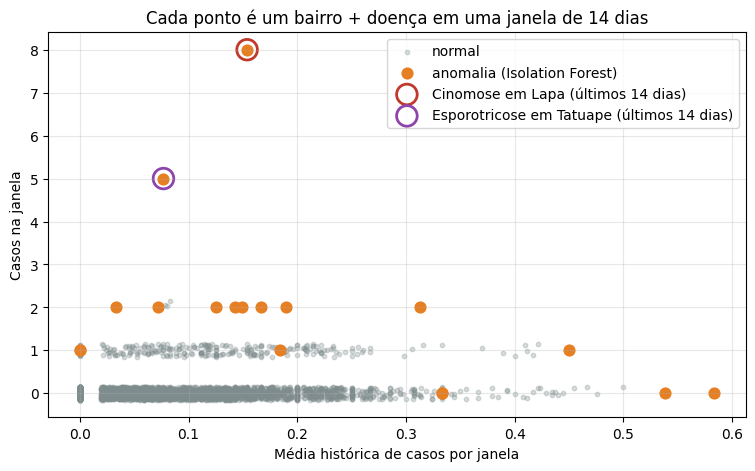

In [15]:
plt.figure(figsize=(9, 5))
normais = pontos_if[~pontos_if["anomalia_if"]]
anomalos = pontos_if[pontos_if["anomalia_if"]]
plt.scatter(normais["media_hist"], normais["casos"] + np.random.default_rng(0).uniform(-0.15, 0.15, len(normais)),
            s=10, alpha=0.3, color="#7f8c8d", label="normal")
plt.scatter(anomalos["media_hist"], anomalos["casos"], s=60, color="#e67e22", label="anomalia (Isolation Forest)")
for bairro, doenca, cor in [("Lapa", "Cinomose", "#c0392b"), ("Tatuape", "Esporotricose", "#8e44ad")]:
    p = pontos_if[(pontos_if["bairro"] == bairro) & (pontos_if["doenca"] == doenca) & (pontos_if["janela"] == 0)]
    plt.scatter(p["media_hist"], p["casos"], s=220, facecolors="none", edgecolors=cor, linewidths=2,
                label=f"{doenca} em {bairro} (últimos 14 dias)")
plt.xlabel("Média histórica de casos por janela")
plt.ylabel("Casos na janela")
plt.title("Cada ponto é um bairro + doença em uma janela de 14 dias")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Parte 3 — Resultado e uso

## 9. Resultado final do Vigia C

In [16]:
alertas_finais = avaliar_regioes(casos, modelo_if)
alertas_finais[["bairro", "doenca", "especie", "casos", "nivel_risco", "confirmado_if", "motivo", "recomendacao"]]

,bairro,doenca,especie,casos,nivel_risco,confirmado_if,motivo,recomendacao
0,Butanta,Raiva,Canina,1,ALTO,False,"Suspeita de raiva em Butanta (1 gato, nos últimos 14 dias). Alerta imediato: doença fatal, transmissível a humanos e de notificação obri...","Confira se a vacina antirrábica dos cães está em dia, evite contato com animais desconhecidos e procure o veterinário ou a vigilância em..."
1,Butanta,Raiva,Felina,1,ALTO,False,"Suspeita de raiva em Butanta (1 gato, nos últimos 14 dias). Alerta imediato: doença fatal, transmissível a humanos e de notificação obri...","Confira se a vacina antirrábica dos gatos está em dia, evite contato com animais desconhecidos e procure o veterinário ou a vigilância e..."
2,Lapa,Cinomose,Canina,8,ALTO,True,"8 casos de Cinomose em Lapa nos últimos 14 dias (média histórica de 0,2 caso(s) a cada 14 dias; doença contagiosa). Confirmado pelo Isol...","Surto provável de cinomose. Confira a vacinação dos cães da região, evite contato com animais doentes e procure o veterinário aos primei..."
3,Tatuape,Esporotricose,Felina,5,ALTO,True,"5 casos de Esporotricose em Tatuape nos últimos 14 dias (média histórica de 0,1 caso(s) a cada 14 dias; doença contagiosa). Confirmado p...","Surto provável de esporotricose. Confira a vacinação dos gatos da região, evite contato com animais doentes e procure o veterinário aos ..."
4,Penha,Leptospirose,Canina,1,BAIXO,False,1 caso(s) de Leptospirose em Penha durante a época de maior incidência (outubro a março). Alerta preventivo.,Época de maior incidência de leptospirose. Mantenha a vacinação dos cães em dia.


## 10. Doenças em surto por bairro (entrada do Vigia B)

In [17]:
doencas_em_surto_por_regiao(alertas_finais)

{('Butanta', 'Canina'): ['Raiva'],
 ('Butanta', 'Felina'): ['Raiva'],
 ('Lapa', 'Canina'): ['Cinomose'],
 ('Tatuape', 'Felina'): ['Esporotricose']}

## 11. Salvando o modelo

In [18]:
joblib.dump({
    "modelo_isolation_forest": modelo_if,
    "features_isolation_forest": FEATURES_IF,
    "contaminacao": modelo_if.contamination,
    "janela_dias": JANELA_DIAS,
    "limiares": LIMIAR,
    "data_referencia": DATA_REFERENCIA,
}, "modelo_vigia_c.joblib", compress=3)
print("Modelo do Vigia C salvo em modelo_vigia_c.joblib")

Modelo do Vigia C salvo em modelo_vigia_c.joblib


## 12. Testando o modelo salvo

In [19]:
pacote = joblib.load("modelo_vigia_c.joblib")
modelo_salvo = pacote["modelo_isolation_forest"]
print("Modelo carregado:", type(modelo_salvo).__name__, "| contaminação:", pacote["contaminacao"])

alertas_salvo = avaliar_regioes(casos, modelo_salvo)
print("Mesmos alertas do notebook:",
      alertas_salvo[["bairro", "doenca", "especie", "nivel_risco", "confirmado_if"]]
      .equals(alertas_finais[["bairro", "doenca", "especie", "nivel_risco", "confirmado_if"]]))
alertas_salvo[["bairro", "doenca", "especie", "casos", "nivel_risco", "confirmado_if"]]

Modelo carregado: IsolationForest | contaminação: 0.005
Mesmos alertas do notebook: True


,bairro,doenca,especie,casos,nivel_risco,confirmado_if
0,Butanta,Raiva,Canina,1,ALTO,False
1,Butanta,Raiva,Felina,1,ALTO,False
2,Lapa,Cinomose,Canina,8,ALTO,True
3,Tatuape,Esporotricose,Felina,5,ALTO,True
4,Penha,Leptospirose,Canina,1,BAIXO,False
